In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [131]:
df = pd.read_csv("./raw_data.csv")

In [132]:
df.head()

,Timestamp (UTC),participant_id,participant_type,duration_seconds,What is your age?,What is your current year of study?,"What is your current CGPA? (Based on 10-point scale. If your institution uses percentages, convert it using your official university formula. Ex: CGPA = Percentage / 9.5 or CGPA = Percentage / 10. For 5-point scales, multiply by 2.)","On a typical day, how many hours of total screen time do you have?",Approximately how many hours do you spend on social media each day?,Approximately how many hours do you spend gaming each day?,...,What do you mainly use AI tools for?,How many times do you shop online in a typical month?,Approximately how many times do you check your phone during a normal study session?,"On average, how many hours do you spend studying outside of classes?",How many hours do you usually sleep per night?,How would you describe your usual sleep schedule?,How productive do you usually feel during your study time?,How focused are you usually while studying?,"How satisfied are you with your current balance between digital activities, studies and personal time?",Which activity takes up most of your free time?
0,02-10-2026 11:00,P-6FA0-7EBA-F99B-F876,registered,163.9,19,3rd Year,8.8,8,1,1,...,Learning concepts; Coding / debugging; Assignm...,2,4,2,6.5,3,3,3,3,Social media
1,02-10-2026 11:03,P-1262-13D5-AD8E-5EB0,guest,147.7,19,3rd Year,10.0,8,3,0,...,Learning concepts; Coding / debugging; Assignm...,1,5,16,7.0,4,5,5,1,Social media
2,02-10-2026 11:04,P-239A-0A79-1CA9-8F30,guest,176.0,20,3rd Year,9.0,9,5,1,...,Learning concepts; Coding / debugging; Assignm...,4,3,3,7.0,3,2,4,3,Social media
3,02-10-2026 11:06,P-49B3-89F9-5D94-4C87,guest,128.4,20,3rd Year,7.6,10,4,0,...,Learning concepts; Coding / debugging; Assignm...,4,4,1,7.0,3,3,3,4,YouTube / OTT
4,02-10-2026 11:06,P-6C80-38F5-0432-9C2B,guest,136.5,20,3rd Year,7.7,13,9,4,...,Learning concepts; Coding / debugging; Assignm...,3,5,1,8.5,1,1,5,1,Social media


# Data Dictionary

Source file: `IDHV_dataset.csv`, one row per survey respondent (83 raw responses). "Observed" values are those present in the raw file; scale endpoints are as defined by the questionnaire.

## Columns removed from the analysis (metadata)

| Column | Meaning |
|---|---|
| `Timestamp (UTC)` | Date and time the response was submitted |
| `participant_id` | Anonymous respondent identifier |
| `participant_type` | Whether the respondent was `registered` or a `guest` |
| `duration_seconds` | Time taken to complete the form |

## Questionnaire columns

| # | Renamed column | Question | Type | Possible values | Scale endpoints |
|---|---|---|---|---|---|
| 1 | `age` | What is your age? | Ordinal category | 16 or below, 17, 18, 19, 20, 21, 22, 23 or above | n/a |
| 2 | `year_of_study` | What is your current year of study? | Ordinal category | 2nd Year, 3rd Year, 4th Year (observed) | n/a |
| 3 | `cgpa` | What is your current CGPA? (10-point scale; percentages converted with the official formula, 5-point scales multiplied by 2) | Numeric | 0 to 10 | 0 = lowest, 10 = highest |
| 4 | `screen_time_hrs` | On a typical day, how many hours of total screen time do you have? | Numeric (hours/day) | Whole hours, observed 2 to 16 | n/a |
| 5 | `social_media_time_hrs` | Approximately how many hours do you spend on social media each day? | Numeric (hours/day) | Whole hours, observed 1 to 16 | n/a |
| 6 | `gaming_time_hrs` | Approximately how many hours do you spend gaming each day? | Numeric (hours/day) | Whole hours, observed 0 to 16 | n/a |
| 7 | `ott_time_hrs` | How many hours do you spend watching YouTube/OTT for entertainment each day? | Numeric (hours/day) | Whole hours, observed 0 to 16 | n/a |
| 8 | `AI_usage` | How often do you use AI tools such as ChatGPT, Gemini, Claude, Copilot, etc.? | Ordinal category | Never, Rarely, Daily, Several times a day | Never = least, Several times a day = most (encoded 0, 1, 2, 3) |
| 9 | `AI_usage_purpose` | What do you mainly use AI tools for? | Multi-select text (separated by `; `) | Learning concepts; Coding / debugging; Assignments; Research; Writing / grammar; Generating ideas; Exam preparation; Personal use; I don't use AI tools | n/a (one 0/1 column per option after encoding) |
| 10 | `monthly_online_shopping` | How many times do you shop online in a typical month? | Numeric (count/month) | Whole numbers, observed 0 to 30 | n/a |
| 11 | `phone_during_study` | Approximately how many times do you check your phone during a normal study session? | Ordinal 1-5 | 1, 2, 3, 4, 5 | **1 = Not at all, 5 = Extremely** (higher = more phone use) |
| 12 | `study_time` | On average, how many hours do you spend studying outside of classes? | Numeric (hours/day) | Whole hours, observed 1 to 16 | n/a |
| 13 | `sleep_time_hrs` | How many hours do you usually sleep per night? | Numeric (hours) | Observed 5 to 16 (half hours allowed) | n/a |
| 14 | `sleep_schedule` | How would you describe your usual sleep schedule? | Ordinal 1-5 | 1, 2, 3, 4, 5 | **1 = Very regular, 5 = Very irregular** (reversed to `sleep_regularity_score`) |
| 15 | `productive_in_study` | How productive do you usually feel during your study time? | Ordinal 1-5 | 1, 2, 3, 4, 5 | **1 = Very productive, 5 = Not productive** (reversed to `productivity_score`) |
| 16 | `focus_during_study` | How focused are you usually while studying? | Ordinal 1-5 | 1, 2, 3, 4, 5 | **1 = Very focused, 5 = Not focused** (reversed to `focus_score`) |
| 17 | `satisfication_of_digital_profile` | How satisfied are you with your current balance between digital activities, studies and personal time? | Ordinal 1-5 | 1, 2, 3, 4, 5 | **1 = Very dissatisfied, 5 = Very satisfied** |
| 18 | `mostly_spent_activity` | Which activity takes up most of your free time? | Nominal category | Social media, YouTube / OTT, Gaming, Studying, AI tools, Online shopping, Friends / Social Activities | n/a |

## Columns created during preprocessing

| Column(s) | Description |
|---|---|
| `AI_usage_encoded` | Ordinal encoding of `AI_usage` (0 Never, 1 Rarely, 2 Daily, 3 Several times a day) |
| `AI_usage_<purpose>` (9 columns) | 0/1 indicator for each AI-purpose option |
| `activity_<name>` (7 columns) | One-hot indicator for each free-time activity |
| `focus_score`, `productivity_score`, `sleep_regularity_score` | Reverse-coded versions (6 - x) so that **higher = better** |
| `n_ai_purposes` | Number of different AI purposes selected |
| `df_scaled` (separate table) | Min-max, z-score and log1p versions of numeric features |

# Drop unnecessary Columns

In [133]:
df.columns

Index(['Timestamp (UTC)', 'participant_id', 'participant_type',
       'duration_seconds', 'What is your age?',
       'What is your current year of study?',
       'What is your current CGPA? (Based on 10-point scale. If your institution uses percentages, convert it using your official university formula. Ex: CGPA = Percentage / 9.5 or CGPA = Percentage / 10. For 5-point scales, multiply by 2.)',
       'On a typical day, how many hours of total screen time do you have?',
       'Approximately how many hours do you spend on social media each day?',
       'Approximately how many hours do you spend gaming each day?',
       'How many hours do you spend watching YouTube/OTT for entertainment each day?',
       'How often do you use AI tools such as ChatGPT, Gemini, Claude, Copilot, etc.?',
       'What do you mainly use AI tools for?',
       'How many times do you shop online in a typical month?',
       'Approximately how many times do you check your phone during a normal study sessio

In [134]:
df_copy = df.drop(columns=['participant_id','duration_seconds','Timestamp (UTC)','participant_type'], axis=1)

In [135]:
df_copy.shape

(83, 18)

In [136]:
df_copy.head()

,What is your age?,What is your current year of study?,"What is your current CGPA? (Based on 10-point scale. If your institution uses percentages, convert it using your official university formula. Ex: CGPA = Percentage / 9.5 or CGPA = Percentage / 10. For 5-point scales, multiply by 2.)","On a typical day, how many hours of total screen time do you have?",Approximately how many hours do you spend on social media each day?,Approximately how many hours do you spend gaming each day?,How many hours do you spend watching YouTube/OTT for entertainment each day?,"How often do you use AI tools such as ChatGPT, Gemini, Claude, Copilot, etc.?",What do you mainly use AI tools for?,How many times do you shop online in a typical month?,Approximately how many times do you check your phone during a normal study session?,"On average, how many hours do you spend studying outside of classes?",How many hours do you usually sleep per night?,How would you describe your usual sleep schedule?,How productive do you usually feel during your study time?,How focused are you usually while studying?,"How satisfied are you with your current balance between digital activities, studies and personal time?",Which activity takes up most of your free time?
0,19,3rd Year,8.8,8,1,1,1,Several times a day,Learning concepts; Coding / debugging; Assignm...,2,4,2,6.5,3,3,3,3,Social media
1,19,3rd Year,10.0,8,3,0,3,Several times a day,Learning concepts; Coding / debugging; Assignm...,1,5,16,7.0,4,5,5,1,Social media
2,20,3rd Year,9.0,9,5,1,2,Daily,Learning concepts; Coding / debugging; Assignm...,4,3,3,7.0,3,2,4,3,Social media
3,20,3rd Year,7.6,10,4,0,1,Daily,Learning concepts; Coding / debugging; Assignm...,4,4,1,7.0,3,3,3,4,YouTube / OTT
4,20,3rd Year,7.7,13,9,4,2,Daily,Learning concepts; Coding / debugging; Assignm...,3,5,1,8.5,1,1,5,1,Social media


# Rename Columns

In [137]:
df_copy.columns=["age", "year_of_study", "cgpa", "screen_time_hrs", "social_media_time_hrs", "gaming_time_hrs", "ott_time_hrs", "AI_usage","AI_usage_purpose", "monthly_online_shopping", "phone_during_study", "study_time", "sleep_time_hrs", "sleep_schedule", "productive_in_study", "focus_during_study", "satisfication_of_digital_profile", "mostly_spent_activity"]

In [138]:
df_copy.head()

,age,year_of_study,cgpa,screen_time_hrs,social_media_time_hrs,gaming_time_hrs,ott_time_hrs,AI_usage,AI_usage_purpose,monthly_online_shopping,phone_during_study,study_time,sleep_time_hrs,sleep_schedule,productive_in_study,focus_during_study,satisfication_of_digital_profile,mostly_spent_activity
0,19,3rd Year,8.8,8,1,1,1,Several times a day,Learning concepts; Coding / debugging; Assignm...,2,4,2,6.5,3,3,3,3,Social media
1,19,3rd Year,10.0,8,3,0,3,Several times a day,Learning concepts; Coding / debugging; Assignm...,1,5,16,7.0,4,5,5,1,Social media
2,20,3rd Year,9.0,9,5,1,2,Daily,Learning concepts; Coding / debugging; Assignm...,4,3,3,7.0,3,2,4,3,Social media
3,20,3rd Year,7.6,10,4,0,1,Daily,Learning concepts; Coding / debugging; Assignm...,4,4,1,7.0,3,3,3,4,YouTube / OTT
4,20,3rd Year,7.7,13,9,4,2,Daily,Learning concepts; Coding / debugging; Assignm...,3,5,1,8.5,1,1,5,1,Social media


# Cleaning Data


## Check for missing values

In [139]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               83 non-null     object 
 1   year_of_study                     83 non-null     object 
 2   cgpa                              83 non-null     float64
 3   screen_time_hrs                   83 non-null     int64  
 4   social_media_time_hrs             83 non-null     int64  
 5   gaming_time_hrs                   83 non-null     int64  
 6   ott_time_hrs                      83 non-null     int64  
 7   AI_usage                          83 non-null     object 
 8   AI_usage_purpose                  83 non-null     object 
 9   monthly_online_shopping           83 non-null     int64  
 10  phone_during_study                83 non-null     int64  
 11  study_time                        83 non-null     int64  
 12  sleep_time

## Check for duplicate values

In [140]:
df_copy.duplicated().sum()

np.int64(0)

## Identifying wrong/unusual data

### Lets inspect age and year combinations

In [141]:
df_copy[['year_of_study', 'age']].value_counts()

year_of_study  age        
3rd Year       19             24
               20             19
2nd Year       19             11
               18              8
4th Year       21              5
               23 or above     4
3rd Year       21              3
4th Year       20              3
2nd Year       20              2
4th Year       22              2
2nd Year       17              1
4th Year       16 or below     1
Name: count, dtype: int64

#### Removing an unusual age and year combination

In [142]:
df_copy = df_copy[~((df_copy['age'] == "16 or below") & (df_copy['year_of_study'] == "4th Year"))]

In [143]:
df_copy[['year_of_study', 'age']].value_counts()

year_of_study  age        
3rd Year       19             24
               20             19
2nd Year       19             11
               18              8
4th Year       21              5
               23 or above     4
3rd Year       21              3
4th Year       20              3
2nd Year       20              2
4th Year       22              2
2nd Year       17              1
Name: count, dtype: int64

### Lets inspect cgpa column

In [144]:
pd.DataFrame(df_copy['cgpa'].value_counts()).sort_values(by='cgpa')

,count
cgpa,
1.7,2
6.6,1
6.7,1
6.8,1
7.0,3
7.1,1
7.2,2
7.3,2
7.4,2


#### Remove invalid cgpa values

In [145]:
df_copy = df_copy[df_copy['cgpa'] > 6.0]

In [146]:
pd.DataFrame(df_copy['cgpa'].value_counts()).sort_values(by='cgpa')

,count
cgpa,
6.6,1
6.7,1
6.8,1
7.0,3
7.1,1
7.2,2
7.3,2
7.4,2
7.6,4


### Handling Inconsistent AI Usage Responses

In [147]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 80 entries, 0 to 82
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   age                               80 non-null     object 
 1   year_of_study                     80 non-null     object 
 2   cgpa                              80 non-null     float64
 3   screen_time_hrs                   80 non-null     int64  
 4   social_media_time_hrs             80 non-null     int64  
 5   gaming_time_hrs                   80 non-null     int64  
 6   ott_time_hrs                      80 non-null     int64  
 7   AI_usage                          80 non-null     object 
 8   AI_usage_purpose                  80 non-null     object 
 9   monthly_online_shopping           80 non-null     int64  
 10  phone_during_study                80 non-null     int64  
 11  study_time                        80 non-null     int64  
 12  sleep_time_hrs 

In [148]:
# Removing rows which have "I don't use AI tools" and some other options selected.
mask = (
    df_copy["AI_usage_purpose"].str.contains(
        "I don't use AI tools",
        case=False,
        na=False
    )
    &
    df_copy["AI_usage_purpose"].str.contains(
        ";",
        na=False
    )
)

display(df_copy.loc[mask, ["AI_usage", "AI_usage_purpose"]])
print("Rows to remove:", mask.sum())

,AI_usage,AI_usage_purpose
63,Daily,Learning concepts; Coding / debugging; Assignm...


Rows to remove: 1


#### Removing unusal value

In [149]:
df_copy = df_copy.loc[~mask].reset_index(drop=True)

print("Updated dataset shape:", df_copy.shape)

Updated dataset shape: (79, 18)


## Handle age and year of study

In [150]:
print(df_copy["age"].value_counts())

age
19             34
20             24
21              8
18              8
23 or above     2
22              2
17              1
Name: count, dtype: int64


In [151]:
year_order = ["2nd Year", "3rd Year", "4th Year"]

df_copy["year_of_study"] = pd.Categorical(
    df_copy["year_of_study"],
    categories=year_order,
    ordered=True
)

In [152]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   age                               79 non-null     object  
 1   year_of_study                     79 non-null     category
 2   cgpa                              79 non-null     float64 
 3   screen_time_hrs                   79 non-null     int64   
 4   social_media_time_hrs             79 non-null     int64   
 5   gaming_time_hrs                   79 non-null     int64   
 6   ott_time_hrs                      79 non-null     int64   
 7   AI_usage                          79 non-null     object  
 8   AI_usage_purpose                  79 non-null     object  
 9   monthly_online_shopping           79 non-null     int64   
 10  phone_during_study                79 non-null     int64   
 11  study_time                        79 non-null     int64   
 

## Encoding

### Handling AI_usage column

In [153]:
ai_usage_map = {
    "Never": 0,
    "Rarely": 1,
    "Daily": 2,
    "Several times a day": 3
}

df_copy["AI_usage_encoded"] = df_copy["AI_usage"].map(ai_usage_map)

In [154]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   age                               79 non-null     object  
 1   year_of_study                     79 non-null     category
 2   cgpa                              79 non-null     float64 
 3   screen_time_hrs                   79 non-null     int64   
 4   social_media_time_hrs             79 non-null     int64   
 5   gaming_time_hrs                   79 non-null     int64   
 6   ott_time_hrs                      79 non-null     int64   
 7   AI_usage                          79 non-null     object  
 8   AI_usage_purpose                  79 non-null     object  
 9   monthly_online_shopping           79 non-null     int64   
 10  phone_during_study                79 non-null     int64   
 11  study_time                        79 non-null     int64   
 

### Handling AI_usage_purpose column

In [155]:
# One Hot Encoding
options = {
    "Learning concepts": "AI_usage_learning_concepts",
    "Coding / debugging": "AI_usage_coding_debugging",
    "Assignments": "AI_usage_assignments",
    "Research": "AI_usage_research",
    "Writing / grammar": "AI_usage_writing_grammar",
    "Generating ideas": "AI_usage_generating_ideas",
    "Exam preparation": "AI_usage_exam_preparation",
    "Personal use": "AI_usage_personal_use",
    "I don't use AI tools": "AI_usage_no_ai_tools"
}

for option, col_name in options.items():
    df_copy[col_name] = df_copy["AI_usage_purpose"].apply(
        lambda x: int(option in x.split("; ")) if pd.notna(x) else 0
    )

display(df_copy.head())

,age,year_of_study,cgpa,screen_time_hrs,social_media_time_hrs,gaming_time_hrs,ott_time_hrs,AI_usage,AI_usage_purpose,monthly_online_shopping,...,AI_usage_encoded,AI_usage_learning_concepts,AI_usage_coding_debugging,AI_usage_assignments,AI_usage_research,AI_usage_writing_grammar,AI_usage_generating_ideas,AI_usage_exam_preparation,AI_usage_personal_use,AI_usage_no_ai_tools
0,19,3rd Year,8.8,8,1,1,1,Several times a day,Learning concepts; Coding / debugging; Assignm...,2,...,3,1,1,1,1,0,1,1,0,0
1,19,3rd Year,10.0,8,3,0,3,Several times a day,Learning concepts; Coding / debugging; Assignm...,1,...,3,1,1,1,1,1,1,1,1,0
2,20,3rd Year,9.0,9,5,1,2,Daily,Learning concepts; Coding / debugging; Assignm...,4,...,2,1,1,1,1,0,0,1,0,0
3,20,3rd Year,7.6,10,4,0,1,Daily,Learning concepts; Coding / debugging; Assignm...,4,...,2,1,1,1,1,1,1,1,1,0
4,20,3rd Year,7.7,13,9,4,2,Daily,Learning concepts; Coding / debugging; Assignm...,3,...,2,1,1,1,1,0,1,1,1,0


In [156]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 28 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   age                               79 non-null     object  
 1   year_of_study                     79 non-null     category
 2   cgpa                              79 non-null     float64 
 3   screen_time_hrs                   79 non-null     int64   
 4   social_media_time_hrs             79 non-null     int64   
 5   gaming_time_hrs                   79 non-null     int64   
 6   ott_time_hrs                      79 non-null     int64   
 7   AI_usage                          79 non-null     object  
 8   AI_usage_purpose                  79 non-null     object  
 9   monthly_online_shopping           79 non-null     int64   
 10  phone_during_study                79 non-null     int64   
 11  study_time                        79 non-null     int64   
 

### Handling mostly_spend_activity column

In [157]:
# One Hot Encoding
activity_options = {
    "Social media": "activity_social_media",
    "Gaming": "activity_gaming",
    "YouTube / OTT": "activity_youtube_ott",
    "Studying": "activity_studying",
    "AI tools": "activity_ai_tools",
    "Online shopping": "activity_online_shopping",
    "Friends / Social Activities": "activity_friends_social_activities"
}

for option, col_name in activity_options.items():
    df_copy[col_name] = (
        df_copy["mostly_spent_activity"] == option
    ).astype(int)

In [158]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 35 columns):
 #   Column                              Non-Null Count  Dtype   
---  ------                              --------------  -----   
 0   age                                 79 non-null     object  
 1   year_of_study                       79 non-null     category
 2   cgpa                                79 non-null     float64 
 3   screen_time_hrs                     79 non-null     int64   
 4   social_media_time_hrs               79 non-null     int64   
 5   gaming_time_hrs                     79 non-null     int64   
 6   ott_time_hrs                        79 non-null     int64   
 7   AI_usage                            79 non-null     object  
 8   AI_usage_purpose                    79 non-null     object  
 9   monthly_online_shopping             79 non-null     int64   
 10  phone_during_study                  79 non-null     int64   
 11  study_time                        

### Reverse-coding the ordinal scales

The questionnaire codes some scales so that **1 is the favourable end** (1 = Very focused, 1 = Very productive, 1 = Very regular). Left as-is, a higher number would mean *worse* focus/productivity/regularity, which makes correlations easy to misread. Three analysis columns are therefore created with the direction flipped (`6 - x`) so that **higher = better** for all of them. The original coded columns are kept unchanged.

| Original column | Original coding | New column | New coding |
|---|---|---|---|
| `focus_during_study` | 1 = Very focused, 5 = Not focused | `focus_score` | 1 = Not focused, 5 = Very focused |
| `productive_in_study` | 1 = Very productive, 5 = Not productive | `productivity_score` | 1 = Not productive, 5 = Very productive |
| `sleep_schedule` | 1 = Very regular, 5 = Very irregular | `sleep_regularity_score` | 1 = Very irregular, 5 = Very regular |

`satisfication_of_digital_profile` (1 = Very dissatisfied, 5 = Very satisfied) and `phone_during_study` (1 = Not at all, 5 = Extremely) already read "higher = more" and are left unchanged. For `phone_during_study`, higher means *more* phone use, i.e. more distraction.

In [159]:
df_copy["focus_score"] = 6 - df_copy["focus_during_study"]
df_copy["productivity_score"] = 6 - df_copy["productive_in_study"]
df_copy["sleep_regularity_score"] = 6 - df_copy["sleep_schedule"]

# Check: reversed columns should be negatively correlated with the originals
for new, old in [("focus_score", "focus_during_study"), ("productivity_score", "productive_in_study"),
                 ("sleep_regularity_score", "sleep_schedule")]:
    print(new, "vs", old, "rho =", round(df_copy[new].corr(df_copy[old], method="spearman"), 3))

focus_score vs focus_during_study rho = -1.0
productivity_score vs productive_in_study rho = -1.0
sleep_regularity_score vs sleep_schedule rho = -1.0


## Statistical Outlier Detection using IQR method

In [160]:
cols = [
    "screen_time_hrs",
    "social_media_time_hrs",
    "gaming_time_hrs",
    "ott_time_hrs",
    "monthly_online_shopping",
    "phone_during_study",
    "study_time",
    "sleep_time_hrs",
]
outlier_results = []
for col in cols:
    q1 = df_copy[col].quantile(0.25)
    q3 = df_copy[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df_copy[col] < lower_bound) |
        (df_copy[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

In [161]:
outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(2).to_string(index=False))

                 Column  Q1   Q3  IQR  Lower Bound  Upper Bound  Outlier Count
        screen_time_hrs 5.0 10.0  5.0         -2.5         17.5              0
  social_media_time_hrs 2.0  5.0  3.0         -2.5          9.5              4
        gaming_time_hrs 0.0  1.0  1.0         -1.5          2.5             10
           ott_time_hrs 1.0  3.0  2.0         -2.0          6.0              5
monthly_online_shopping 1.0  3.0  2.0         -2.0          6.0              6
     phone_during_study 3.0  4.0  1.0          1.5          5.5              1
             study_time 2.0  4.0  2.0         -1.0          7.0              4
         sleep_time_hrs 6.0  8.0  2.0          3.0         11.0              1


In [162]:
# Find the index of all the outliers in the data
for col in cols:
    q1 = df_copy[col].quantile(0.25)
    q3 = df_copy[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df_copy.loc[
        (df_copy[col] < lower) | (df_copy[col] > upper),
        col
    ]

    if not outliers.empty:
        print(f"\n{col}")
        print(outliers.to_string())



social_media_time_hrs
36    16
49    12
65    10
73    10

gaming_time_hrs
4      4
12     3
17     5
24     3
27     5
33     4
36    16
42     3
47     5
49     4

ott_time_hrs
16     7
25     8
36    13
42     8
65     9

monthly_online_shopping
23     8
24    12
36    26
56    11
64     9
70     7

phone_during_study
28    1

study_time
1     16
24    10
36    16
58     8

sleep_time_hrs
36    16.0


As many responses have a very low gaming time, the data cluster around 0 and 1, so many IQR "outliers" in `gaming_time_hrs` are expected and are not errors.

### Inspect unusal outlier indices

In [163]:
df_copy.loc[65]

age                                                                                  19
year_of_study                                                                  3rd Year
cgpa                                                                                9.0
screen_time_hrs                                                                      12
social_media_time_hrs                                                                10
gaming_time_hrs                                                                       2
ott_time_hrs                                                                          9
AI_usage                                                                          Daily
AI_usage_purpose                      Learning concepts; Coding / debugging; Assignm...
monthly_online_shopping                                                               0
phone_during_study                                                                    4
study_time                      

In [164]:
### Index 36 is observed too much. So lets inspect it.
df_copy.loc[36]

age                                                                         23 or above
year_of_study                                                                  4th Year
cgpa                                                                                8.9
screen_time_hrs                                                                      14
social_media_time_hrs                                                                16
gaming_time_hrs                                                                      16
ott_time_hrs                                                                         13
AI_usage                                                                          Daily
AI_usage_purpose                      Coding / debugging; Research; Writing / gramma...
monthly_online_shopping                                                              26
phone_during_study                                                                    4
study_time                      

### Exclusion of an Inconsistent Response

In [165]:
df_copy = df_copy.drop(index=36).reset_index(drop=True)

In [166]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 38 columns):
 #   Column                              Non-Null Count  Dtype   
---  ------                              --------------  -----   
 0   age                                 78 non-null     object  
 1   year_of_study                       78 non-null     category
 2   cgpa                                78 non-null     float64 
 3   screen_time_hrs                     78 non-null     int64   
 4   social_media_time_hrs               78 non-null     int64   
 5   gaming_time_hrs                     78 non-null     int64   
 6   ott_time_hrs                        78 non-null     int64   
 7   AI_usage                            78 non-null     object  
 8   AI_usage_purpose                    78 non-null     object  
 9   monthly_online_shopping             78 non-null     int64   
 10  phone_during_study                  78 non-null     int64   
 11  study_time                        

In [167]:
df_copy['phone_during_study'].value_counts()

phone_during_study
3    29
4    25
2    13
5    10
1     1
Name: count, dtype: int64

# Exploratory Data Analysis

In [168]:
print("Shape:", df_copy.shape)
print("Missing values:", df_copy.isnull().sum().sum())
print("Duplicate rows:", df_copy.duplicated().sum())

display(df_copy.describe(include="all").T)

Shape: (78, 38)
Missing values: 0
Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,78,7,19,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_of_study,78,3,3rd Year,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cgpa,78.0,NaN,NaN,NaN,8.288462,0.763107,6.6,7.7,8.3,8.9,10.0
screen_time_hrs,78.0,NaN,NaN,NaN,7.205128,3.212633,2.0,5.0,7.0,10.0,16.0
social_media_time_hrs,78.0,NaN,NaN,NaN,3.961538,2.381979,1.0,2.0,4.0,5.0,12.0
gaming_time_hrs,78.0,NaN,NaN,NaN,0.923077,1.316915,0.0,0.0,0.0,1.0,5.0
ott_time_hrs,78.0,NaN,NaN,NaN,2.205128,1.969633,0.0,1.0,2.0,3.0,9.0
AI_usage,78,3,Daily,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_usage_purpose,78,36,Learning concepts; Coding / debugging; Assignm...,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_online_shopping,78.0,NaN,NaN,NaN,2.24359,2.439853,0.0,1.0,2.0,3.0,12.0


In [169]:
df_eda = df_copy.copy()

## Visualizing Statistical Outliers

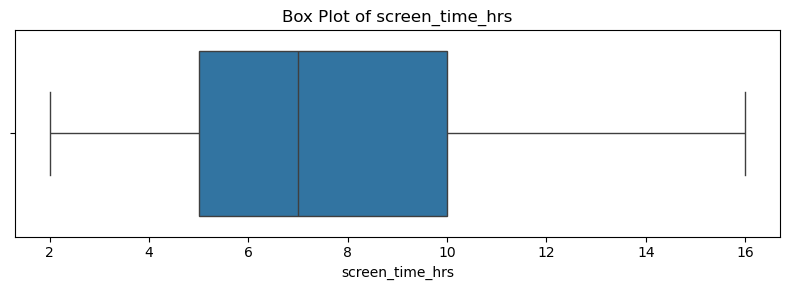

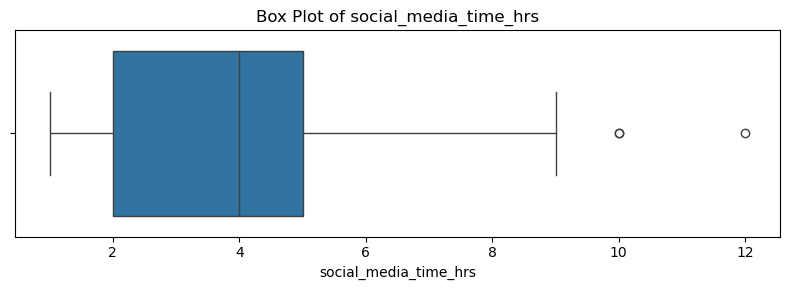

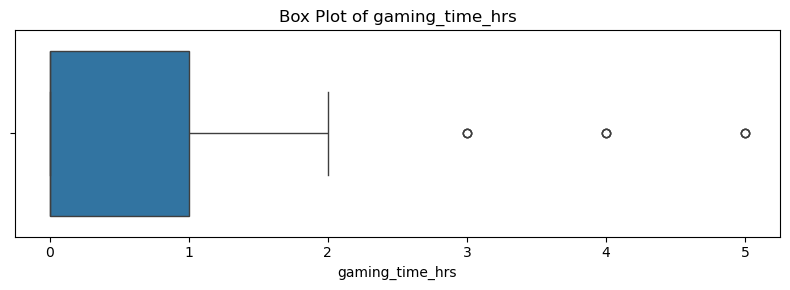

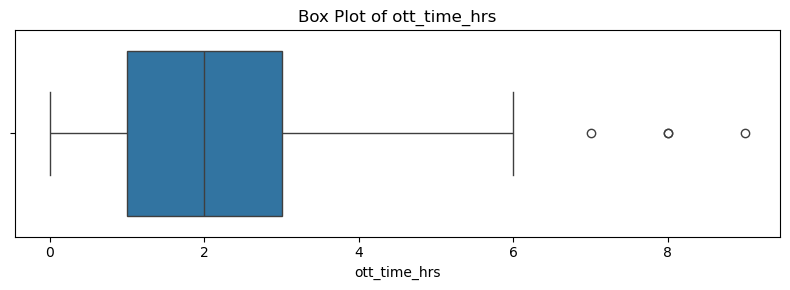

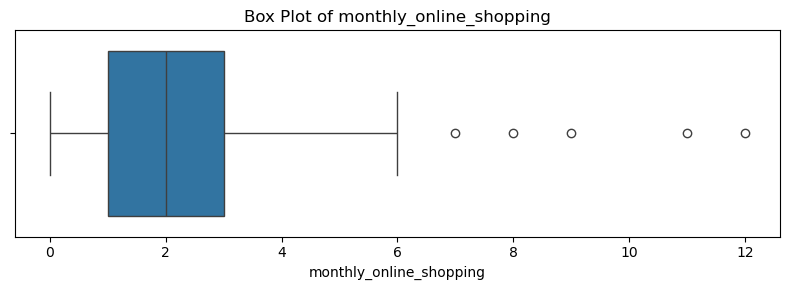

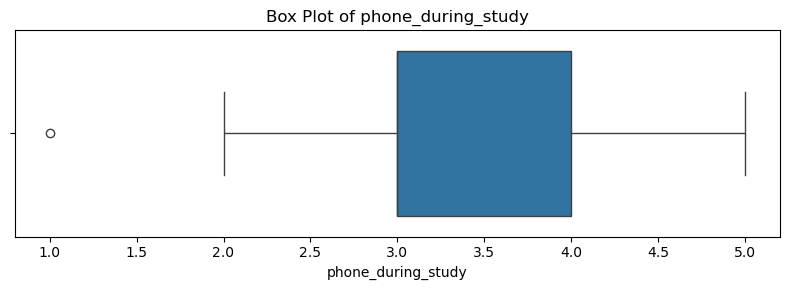

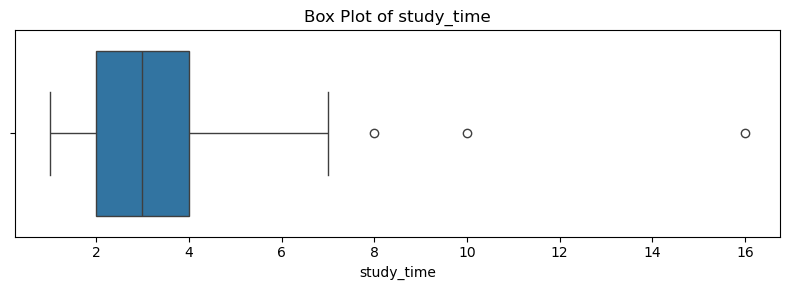

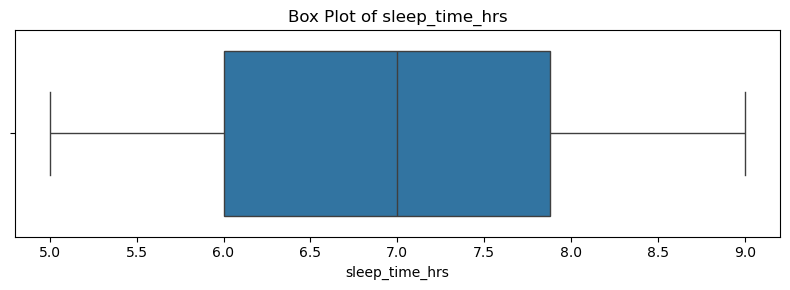

In [170]:
plot_cols = [
    col for col in [
        "cgpa",
        "screen_time_hrs",
        "social_media_time_hrs",
        "gaming_time_hrs",
        "ott_time_hrs",
        "study_time_hrs",
        "sleep_time_hrs"
    ]
    if col in df_copy.columns
]

for col in cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df_copy[col])
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


## Outlier Treatment (Winsorization)

Instead of removing rows containing outliers directly, the method of Winsorization can be used. It replaces outliers with capped boundary values.
Here **capped** boundaries are at IQR fences (Q1 - 1.5*IQR, Q3 + 1.5*IQR).
For `gaming_time_hrs` and `monthly_online_shopping`, where most answers are 0-1 and the IQR is degenerate, high values are capped at the 95th percentile instead.

In [171]:
df_raw = df_copy.copy()

activity_sum = df_copy[["social_media_time_hrs", "gaming_time_hrs", "ott_time_hrs"]].sum(axis=1)
inconsistent = df_copy["screen_time_hrs"] < activity_sum
print("Rows where social + gaming + OTT > total screen time:", inconsistent.sum())
# Activities can overlap with other screen use (multitasking), so these rows are flagged but kept.

iqr_cols = ["screen_time_hrs", "social_media_time_hrs", "ott_time_hrs", "study_time", "sleep_time_hrs"] # Capped at IQR fences
pct_cols = ["gaming_time_hrs", "monthly_online_shopping"] # 95th percentile capped

cap_log = []
for col in iqr_cols + pct_cols:
    if col in iqr_cols:
        q1, q3 = df_copy[col].quantile([0.25, 0.75])
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        lo = max(lo, df_raw[col].min())
    else:
        lo, hi = df_copy[col].min(), df_copy[col].quantile(0.95)
    n_capped = ((df_copy[col] < lo) | (df_copy[col] > hi)).sum()
    df_copy[col] = df_copy[col].clip(lo, hi)
    cap_log.append({"Column": col, "Lower cap": lo, "Upper cap": hi, "Values capped": n_capped,
                    "Max before": df_raw[col].max(), "Max after": df_copy[col].max()})

display(pd.DataFrame(cap_log).round(2))

Rows where social + gaming + OTT > total screen time: 30


,Column,Lower cap,Upper cap,Values capped,Max before,Max after
0,screen_time_hrs,2.0,17.50,0,16.0,16.00
1,social_media_time_hrs,1.0,9.50,3,12.0,9.50
2,ott_time_hrs,0.0,6.00,4,9.0,6.00
3,study_time,1.0,7.00,3,16.0,7.00
4,sleep_time_hrs,5.0,10.69,0,9.0,9.00
5,gaming_time_hrs,0.0,4.00,3,5.0,4.00
6,monthly_online_shopping,0.0,7.15,4,12.0,7.15


## Normalization / Scaling

Variables are on very different scales (CGPA 0-10, hours 0-16, shopping counts, Likert 1-5). For distance- or regression-based methods they should be put on a common scale. Two versions are created in `df_scaled` (the original columns in `df_copy` are left untouched for interpretability):

- **Min-Max** scaling to [0, 1]
- **Z-score** standardization (mean 0, std 1)

Highly right-skewed count/hour variables are additionally `log1p`-transformed.

In [172]:
scale_cols = ["cgpa", "screen_time_hrs", "social_media_time_hrs", "gaming_time_hrs", "ott_time_hrs",
              "monthly_online_shopping", "study_time", "sleep_time_hrs"]

# Skewness before and after log1p transformation
skew_tbl = pd.DataFrame({
    "skew": df_copy[scale_cols].skew(),
    "skew_after_log1p": np.log1p(df_copy[scale_cols]).skew()
}).round(2)
display(skew_tbl)

df_scaled = pd.DataFrame(index=df_copy.index)
for col in scale_cols:
    s = df_copy[col]
    df_scaled[col + "_minmax"] = (s - s.min()) / (s.max() - s.min())
    df_scaled[col + "_z"] = (s - s.mean()) / s.std(ddof=0)

# log1p for the skewed variables (|skew| > 1)
for col in skew_tbl.index[skew_tbl["skew"].abs() > 1]:
    df_scaled[col + "_log1p"] = np.log1p(df_copy[col])

print("Scaled shape:", df_scaled.shape)
print(df_scaled.head())
display(df_scaled.describe().T[["mean", "std", "min", "max"]].round(2))

,skew,skew_after_log1p
cgpa,-0.19,-0.36
screen_time_hrs,0.45,-0.36
social_media_time_hrs,0.81,-0.13
gaming_time_hrs,1.46,0.73
ott_time_hrs,1.10,0.01
monthly_online_shopping,1.08,-0.03
study_time,0.62,-0.03
sleep_time_hrs,0.23,-0.00


Scaled shape: (78, 19)
   cgpa_minmax    cgpa_z  screen_time_hrs_minmax  screen_time_hrs_z  \
0     0.647059  0.674675                0.428571           0.249022   
1     1.000000  2.257371                0.428571           0.249022   
2     0.705882  0.938458                0.500000           0.562308   
3     0.294118 -0.908021                0.571429           0.875594   
4     0.323529 -0.776130                0.785714           1.815451   

   social_media_time_hrs_minmax  social_media_time_hrs_z  \
0                      0.000000                -1.302357   
1                      0.235294                -0.409312   
2                      0.470588                 0.483733   
3                      0.352941                 0.037210   
4                      0.941176                 2.269822   

   gaming_time_hrs_minmax  gaming_time_hrs_z  ott_time_hrs_minmax  \
0                    0.25           0.096308             0.166667   
1                    0.00          -0.738359       

,mean,std,min,max
cgpa_minmax,0.50,0.22,0.00,1.00
cgpa_z,0.00,1.01,-2.23,2.26
screen_time_hrs_minmax,0.37,0.23,0.00,1.00
screen_time_hrs_z,-0.00,1.01,-1.63,2.76
social_media_time_hrs_minmax,0.34,0.27,0.00,1.00
social_media_time_hrs_z,0.00,1.01,-1.30,2.49
gaming_time_hrs_minmax,0.22,0.30,0.00,1.00
gaming_time_hrs_z,0.00,1.01,-0.74,2.60
ott_time_hrs_minmax,0.35,0.28,0.00,1.00
ott_time_hrs_z,-0.00,1.01,-1.25,2.33


## Save the Final Cleaned Dataset

`df_copy` is cleaned, encoded, reverse-coded and outlier-treated data (78 rows). 

In [173]:
df_copy.to_csv("cleaned_data.csv", index=False)
print("Saved cleaned_data.csv:", df_copy.shape)

Saved cleaned_data.csv: (78, 38)


## Plot numerical variable distributions

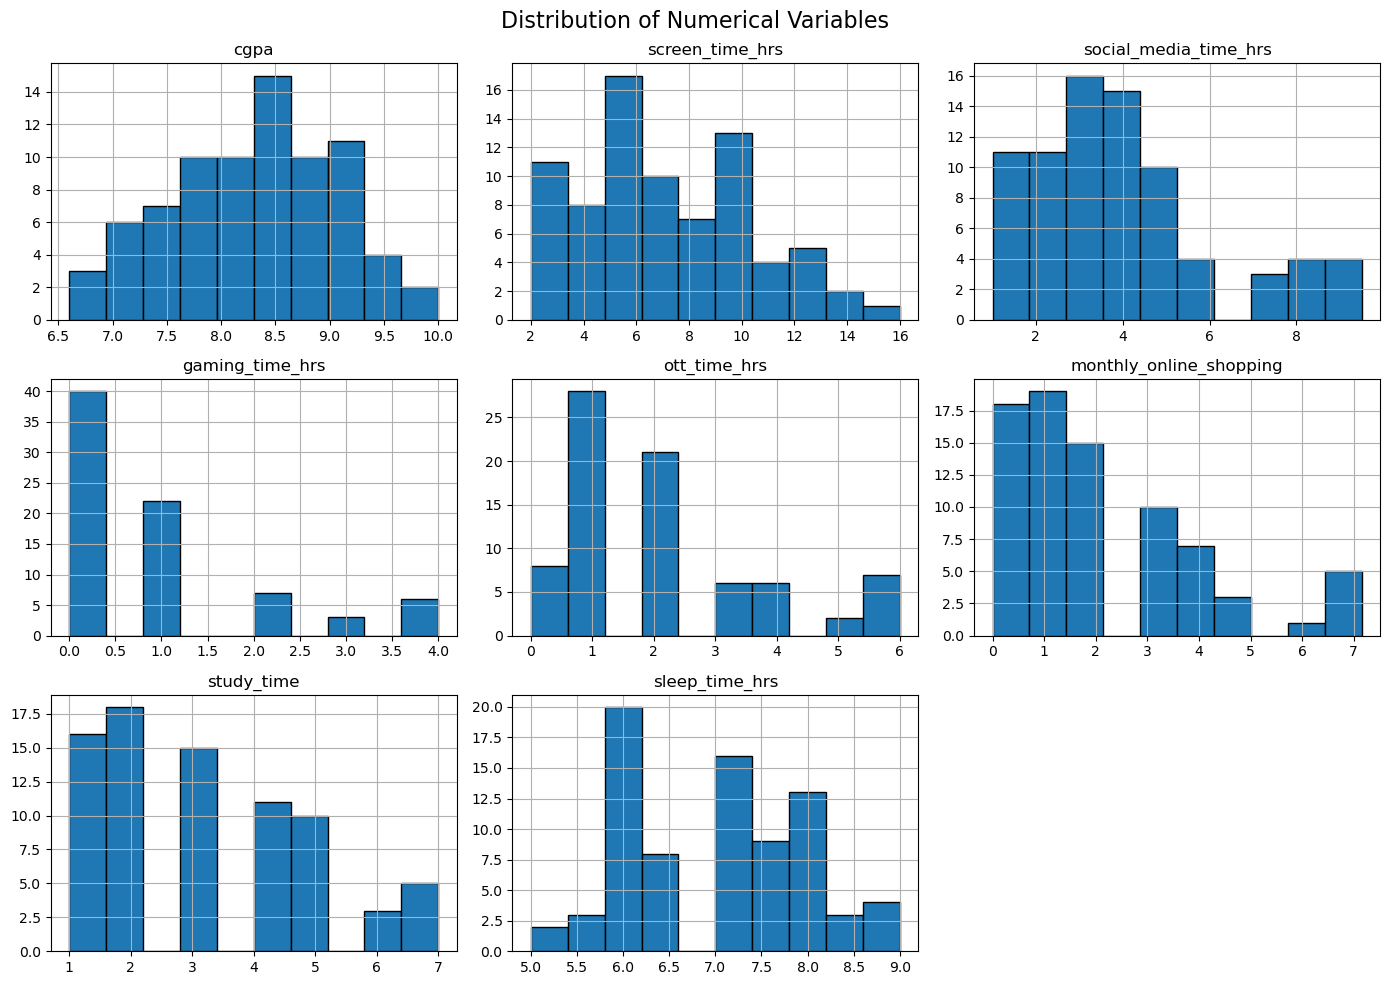

In [174]:
numeric_cols = [
    "cgpa",
    "screen_time_hrs",
    "social_media_time_hrs",
    "gaming_time_hrs",
    "ott_time_hrs",
    "monthly_online_shopping",
    "study_time",
    "sleep_time_hrs"
]

df_copy[numeric_cols].hist(
    figsize=(14, 10),
    bins=10,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

## Plot categorical variables

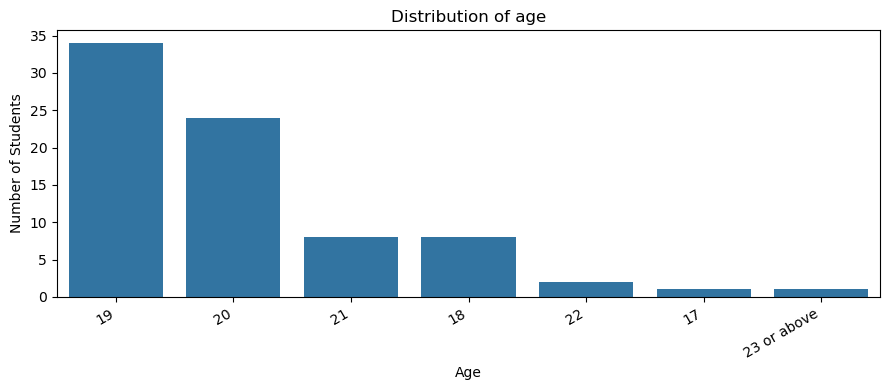

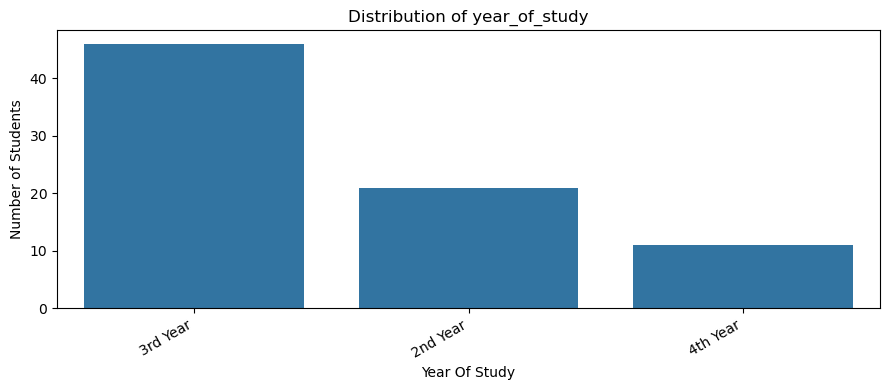

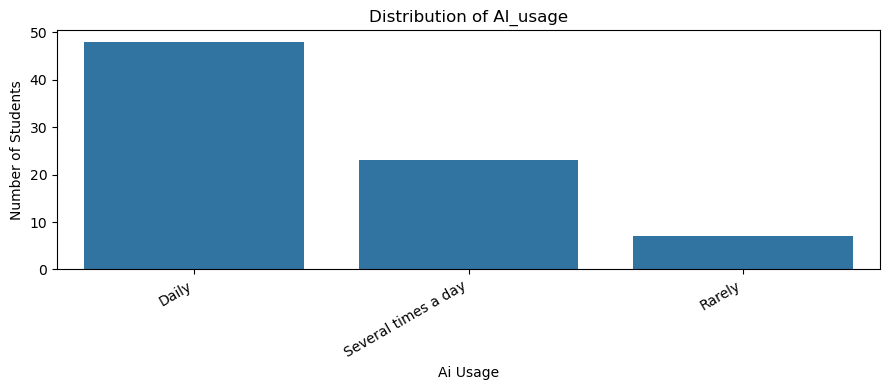

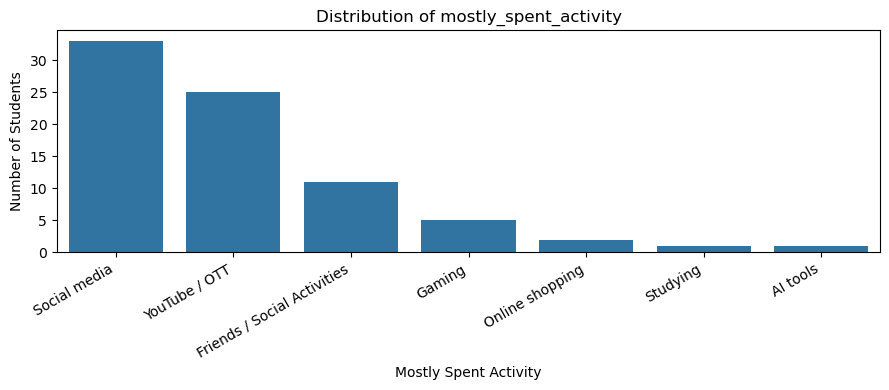

In [175]:
categorical_cols = [
    "age",
    "year_of_study",
    "AI_usage",
    "mostly_spent_activity"
]

for col in categorical_cols:
    plt.figure(figsize=(9, 4))

    order = df_copy[col].value_counts().index

    sns.countplot(
        data=df_copy,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Number of Students")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## Examine Likert-scale responses

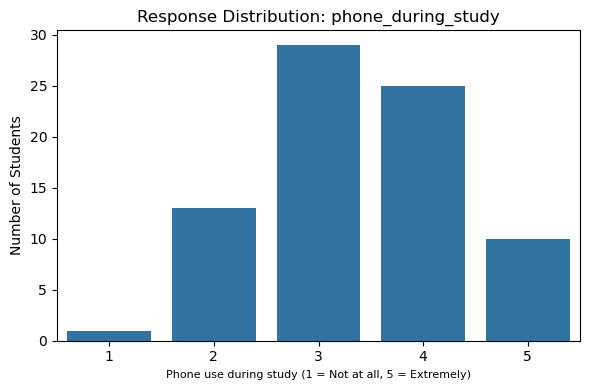

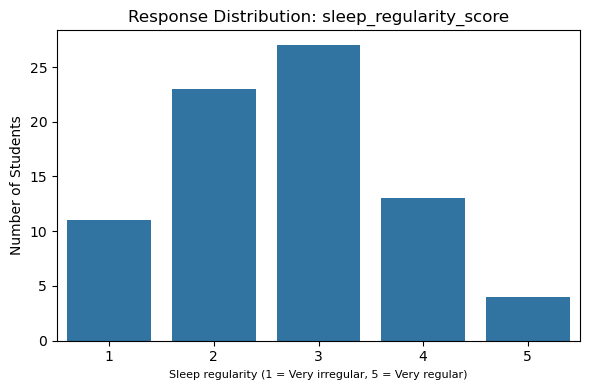

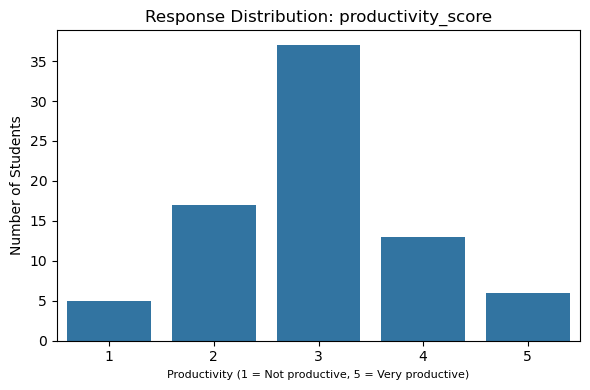

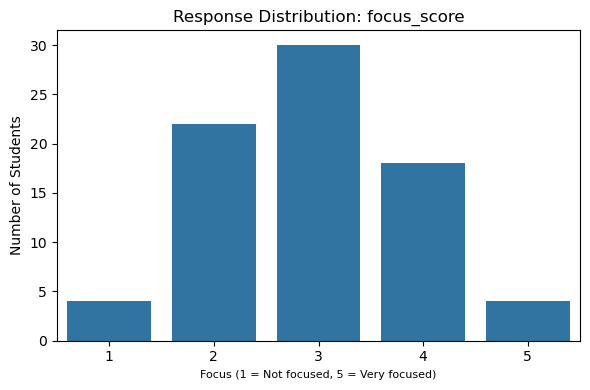

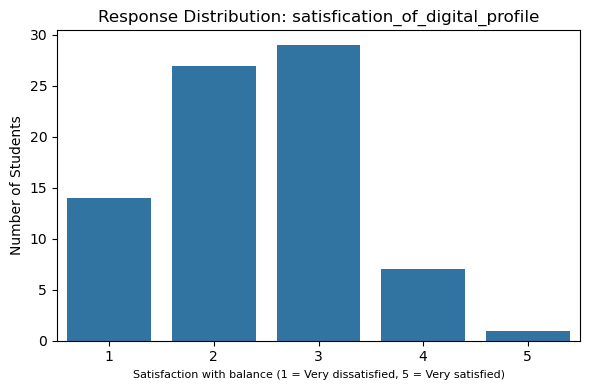

In [176]:
likert_cols = {
    "phone_during_study": "Phone use during study (1 = Not at all, 5 = Extremely)",
    "sleep_regularity_score": "Sleep regularity (1 = Very irregular, 5 = Very regular)",
    "productivity_score": "Productivity (1 = Not productive, 5 = Very productive)",
    "focus_score": "Focus (1 = Not focused, 5 = Very focused)",
    "satisfication_of_digital_profile": "Satisfaction with balance (1 = Very dissatisfied, 5 = Very satisfied)"
}

for col, label in likert_cols.items():
    counts = df_copy[col].value_counts().sort_index()

    plt.figure(figsize=(6, 4))
    sns.barplot(x=counts.index, y=counts.values)

    plt.title(f"Response Distribution: {col}")
    plt.xlabel(label, fontsize=8)
    plt.ylabel("Number of Students")
    plt.tight_layout()
    plt.show()

In [177]:
display(df_copy[numeric_cols].describe().T.round(2))

for col in categorical_cols:
    print(f"\n{col}")
    display(
        df_copy[col]
        .value_counts()
        .rename_axis("Category")
        .reset_index(name="Count")
        .assign(
            Percentage=lambda x: (
                x["Count"] / len(df_copy) * 100
            ).round(2)
        )
    )

,count,mean,std,min,25%,50%,75%,max
cgpa,78.0,8.29,0.76,6.6,7.7,8.3,8.90,10.00
screen_time_hrs,78.0,7.21,3.21,2.0,5.0,7.0,10.00,16.00
social_media_time_hrs,78.0,3.92,2.25,1.0,2.0,4.0,5.00,9.50
gaming_time_hrs,78.0,0.88,1.21,0.0,0.0,0.0,1.00,4.00
ott_time_hrs,78.0,2.10,1.69,0.0,1.0,2.0,3.00,6.00
monthly_online_shopping,78.0,2.10,1.98,0.0,1.0,2.0,3.00,7.15
study_time,78.0,3.13,1.76,1.0,2.0,3.0,4.00,7.00
sleep_time_hrs,78.0,6.97,0.98,5.0,6.0,7.0,7.88,9.00



age


,Category,Count,Percentage
0,19,34,43.59
1,20,24,30.77
2,21,8,10.26
3,18,8,10.26
4,22,2,2.56
5,17,1,1.28
6,23 or above,1,1.28



year_of_study


,Category,Count,Percentage
0,3rd Year,46,58.97
1,2nd Year,21,26.92
2,4th Year,11,14.10



AI_usage


,Category,Count,Percentage
0,Daily,48,61.54
1,Several times a day,23,29.49
2,Rarely,7,8.97



mostly_spent_activity


,Category,Count,Percentage
0,Social media,33,42.31
1,YouTube / OTT,25,32.05
2,Friends / Social Activities,11,14.10
3,Gaming,5,6.41
4,Online shopping,2,2.56
5,Studying,1,1.28
6,AI tools,1,1.28


### Key Findings: Categorical Variables

Based on the responses collected from 78 students, the following observations were made:

- **Year of Study:** The majority of respondents, 46 students (58.97%), belong to the third year of study.
- **AI Usage Frequency:** 48 students (61.54%) reported using AI tools daily, while 23 students (29.49%) reported using them several times a day. This indicates that AI tools are frequently used among the respondents.
- **Most Time-Spent Activity:** Social media was the most commonly selected activity, reported by 33 students (42.31%).
- **YouTube / OTT:** A total of 25 students (32.05%) selected YouTube / OTT as the activity on which they spend the most time.

**Overall Observation:** Social media and YouTube / OTT were the two most frequently selected primary activities. Additionally, the responses indicate that AI tool usage is common among the surveyed students. These findings describe the sample and should not be generalized to all college students without considering the sampling method and sample composition.

## Bivariate EDA — relationships between variables

### Correlation between digital habits and CGPA Using Spearman Correlation

if Spearman Correlation = +1 -> perfect positive correlation

if 0 -> no monotonic correlation

if -1 -> perfect negative correlation

In [178]:
from scipy.stats import spearmanr

relationship_cols = [
    "cgpa",
    "screen_time_hrs",
    "social_media_time_hrs",
    "gaming_time_hrs",
    "ott_time_hrs",
    "study_time",
    "sleep_time_hrs"
]

results = []

for col in relationship_cols:
    if col == "cgpa":
        continue

    temp = df_copy[["cgpa", col]].dropna()
    rho, p_value = spearmanr(temp["cgpa"], temp[col])

    results.append({
        "Variable": col,
        "Spearman Correlation": round(rho, 3),
        "P-value": round(p_value, 4)
    })

correlation_results = pd.DataFrame(results)
display(
    correlation_results.sort_values(
        "Spearman Correlation",
        ascending=False
    )
)

,Variable,Spearman Correlation,P-value
4,study_time,0.140,0.2215
2,gaming_time_hrs,-0.010,0.9317
0,screen_time_hrs,-0.012,0.9141
3,ott_time_hrs,-0.098,0.3935
1,social_media_time_hrs,-0.113,0.3264
5,sleep_time_hrs,-0.140,0.2206


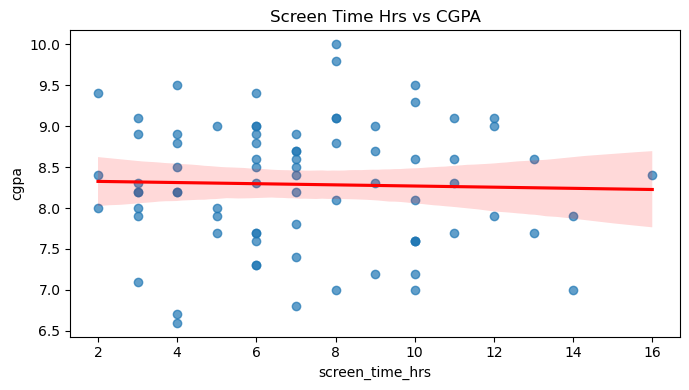

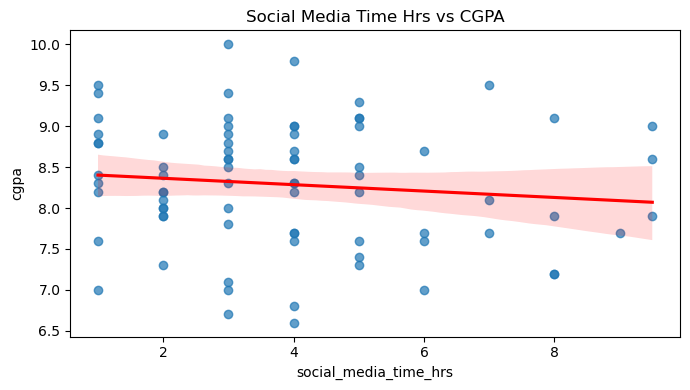

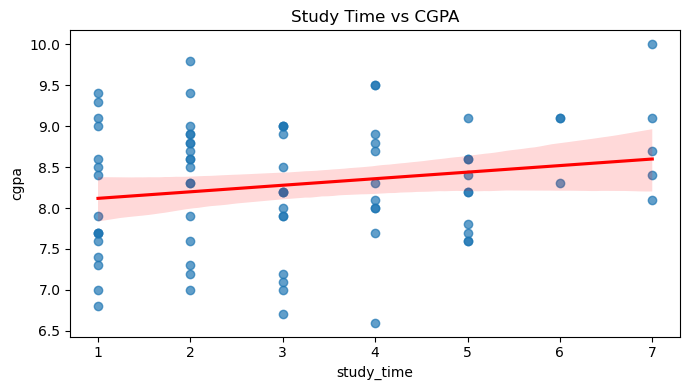

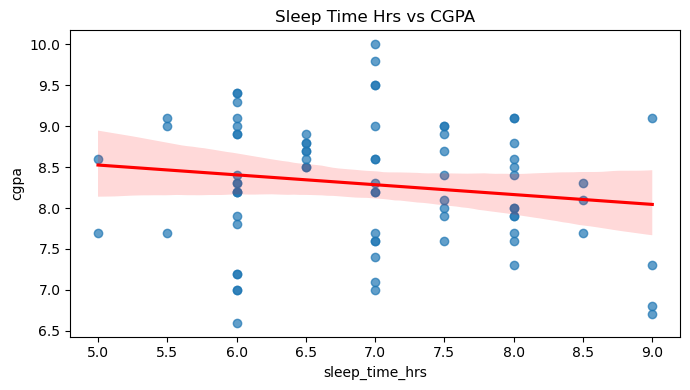

In [179]:
plot_vars = [
    "screen_time_hrs",
    "social_media_time_hrs",
    "study_time",
    "sleep_time_hrs"
]

for col in plot_vars:
    plt.figure(figsize=(7, 4))

    sns.regplot(
        data=df_copy,
        x=col,
        y="cgpa",
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )

    plt.title(f"{col.replace('_', ' ').title()} vs CGPA")
    plt.tight_layout()
    plt.show()

### Compare CGPA across AI-use frequency

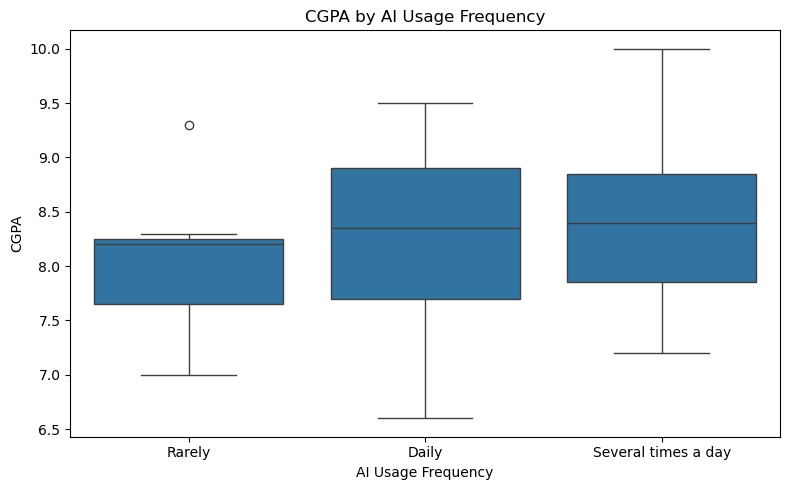

In [180]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_copy,
    x="AI_usage",
    y="cgpa",
    order=["Rarely", "Daily", "Several times a day"]
)

plt.title("CGPA by AI Usage Frequency")
plt.xlabel("AI Usage Frequency")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()

### Findings: Correlation Between Digital Habits and CGPA

Spearman's rank correlation was used to examine the associations between students' digital habits and CGPA.

Study time showed a weak positive correlation with CGPA (\(\rho = 0.140\)), whereas screen time (\(\rho = -0.012\)) and gaming time (\(\rho = -0.010\)) showed almost no monotonic association. Social media time (\(\rho = -0.113\)), OTT time (\(\rho = -0.098\)), and sleep duration (\(\rho = -0.140\)) showed weak negative associations.

None of the observed correlations was statistically significant at the 5% level (\(p > 0.05\)). Therefore, the analysis does not provide sufficient statistical evidence of a monotonic relationship between these individual variables and CGPA in this sample of 78 students.

These findings should be interpreted cautiously because the sample is relatively small, and correlation does not establish causation.

(Values are computed after outlier capping; the conclusion is unchanged from the uncapped data.)

## Analyze focus, productivity, and phone distraction

In [181]:
from scipy.stats import spearmanr

variables = [
    "screen_time_hrs",
    "social_media_time_hrs",
    "phone_during_study",
    "focus_score",
    "productivity_score",
    "sleep_time_hrs",
    "AI_usage_encoded"
]

results = []

for col in variables:
    for target in ["focus_score", "productivity_score"]:
        if col == target:
            continue

        temp = df_copy[[col, target]].dropna()
        rho, p = spearmanr(temp[col], temp[target])

        results.append({
            "Variable": col,
            "Outcome": target,
            "Spearman Correlation": round(rho, 3),
            "P-value": round(p, 4)
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "P-value"
    ).reset_index(drop=True)
)

,Variable,Outcome,Spearman Correlation,P-value
0,focus_score,productivity_score,0.486,0.0000
1,productivity_score,focus_score,0.486,0.0000
2,phone_during_study,focus_score,-0.374,0.0007
3,phone_during_study,productivity_score,-0.237,0.0369
4,sleep_time_hrs,focus_score,-0.179,0.1168
5,sleep_time_hrs,productivity_score,-0.174,0.1272
6,screen_time_hrs,productivity_score,0.135,0.2392
7,social_media_time_hrs,focus_score,-0.128,0.2646
8,screen_time_hrs,focus_score,-0.117,0.3058
9,AI_usage_encoded,focus_score,-0.115,0.3170


### Findings: Digital Habits, Focus, and Productivity

Spearman's rank correlation was used to relate digital habits to study focus and self-reported productivity. Focus and productivity are shown as scores where **higher = better** (1 = Not focused / Not productive, 5 = Very focused / Very productive; reversed from the questionnaire coding). `phone_during_study` runs from 1 = Not at all to 5 = Extremely.

- **Focus and productivity** are moderately and positively associated (\(\rho = 0.486,\ p < 0.0001\)): students who feel more focused also feel more productive.
- **Phone use during study** is negatively associated with focus (\(\rho = -0.374,\ p = 0.0007\)) and, more weakly, with productivity (\(\rho = -0.237,\ p = 0.0369\)). The more students report using their phone while studying, the less focused and productive they feel.
- **Sleep duration** showed weak negative associations with both focus (\(\rho = -0.179,\ p = 0.1168\)) and productivity (\(\rho = -0.174,\ p = 0.1272\)); neither is significant at the 5% level.
- **Screen time** (\(\rho = 0.135,\ p = 0.2392\) with productivity) and **social media time** (\(\rho = -0.128,\ p = 0.2646\) with focus) were not significantly associated with either outcome. **AI-use frequency** showed essentially no association (\(|\rho| \le 0.115\)).

Overall, phone use during study is the clearest digital correlate of reduced focus and productivity. These are associations from self-reported data in a small sample (n = 78) and do not establish causation.

## Focus vs. productivity

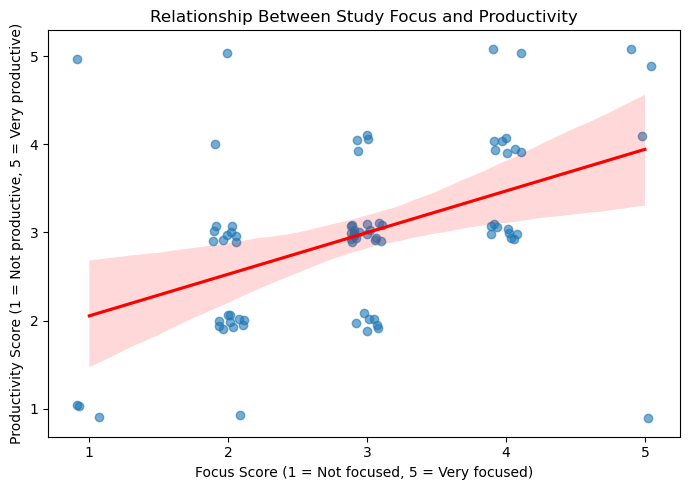

In [182]:
plt.figure(figsize=(7, 5))

sns.regplot(
    data=df_copy,
    x="focus_score",
    y="productivity_score",
    x_jitter=0.12,
    y_jitter=0.12,
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Study Focus and Productivity")
plt.xlabel("Focus Score (1 = Not focused, 5 = Very focused)")
plt.ylabel("Productivity Score (1 = Not productive, 5 = Very productive)")
plt.tight_layout()
plt.show()

## Phone-Usage during study vs. focus

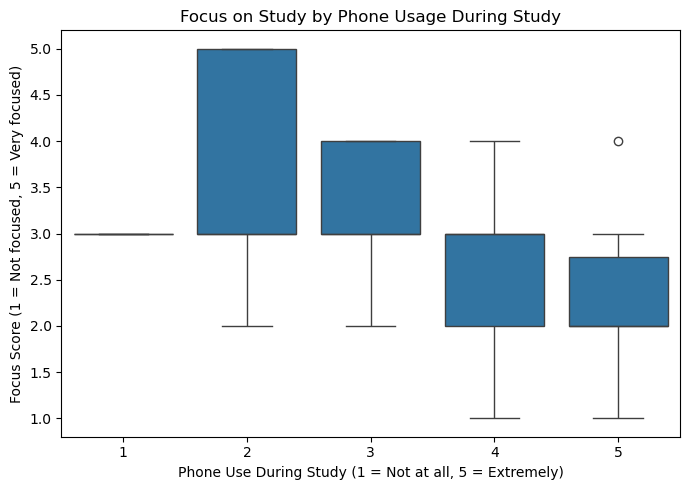

In [183]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_copy,
    x="phone_during_study",
    y="focus_score"
)

plt.title("Focus on Study by Phone Usage During Study")
plt.xlabel("Phone Use During Study (1 = Not at all, 5 = Extremely)")
plt.ylabel("Focus Score (1 = Not focused, 5 = Very focused)")
plt.tight_layout()
plt.show()

## Descriptive Statistics (after cleaning and outlier treatment)

Central tendency (mean, median, mode), spread (std, IQR, coefficient of variation) and shape (skewness, kurtosis) for all numeric variables.

In [184]:
desc_cols = scale_cols + ["sleep_regularity_score", "productivity_score", "focus_score",
                          "satisfication_of_digital_profile", "phone_during_study"]
d = df_copy[desc_cols]
desc = pd.DataFrame({
    "mean": d.mean(), "median": d.median(), "mode": d.mode().iloc[0],
    "std": d.std(), "min": d.min(), "max": d.max(),
    "IQR": d.quantile(0.75) - d.quantile(0.25),
    "CV %": d.std() / d.mean() * 100,
    "skew": d.skew(), "kurtosis": d.kurt()
}).round(2)
display(desc)

,mean,median,mode,std,min,max,IQR,CV %,skew,kurtosis
cgpa,8.29,8.3,7.7,0.76,6.6,10.00,1.20,9.21,-0.19,-0.50
screen_time_hrs,7.21,7.0,6.0,3.21,2.0,16.00,5.00,44.59,0.45,-0.33
social_media_time_hrs,3.92,4.0,3.0,2.25,1.0,9.50,3.00,57.55,0.81,0.15
gaming_time_hrs,0.88,0.0,0.0,1.21,0.0,4.00,1.00,136.31,1.46,1.27
ott_time_hrs,2.10,2.0,1.0,1.69,0.0,6.00,2.00,80.24,1.10,0.41
monthly_online_shopping,2.10,2.0,1.0,1.98,0.0,7.15,2.00,94.48,1.08,0.62
study_time,3.13,3.0,2.0,1.76,1.0,7.00,2.00,56.29,0.62,-0.47
sleep_time_hrs,6.97,7.0,6.0,0.98,5.0,9.00,1.88,14.13,0.23,-0.70
sleep_regularity_score,2.69,3.0,3.0,1.07,1.0,5.00,1.00,39.85,0.20,-0.50
productivity_score,2.97,3.0,3.0,0.98,1.0,5.00,1.00,32.95,0.14,0.03


In [185]:
# D'Agostino-Pearson normality test (H0: data are normally distributed)
from scipy.stats import normaltest
norm = pd.DataFrame([{"Variable": c, "Statistic": normaltest(df_copy[c])[0], "p-value": normaltest(df_copy[c])[1]} for c in scale_cols]).round(4)
norm["Normal at 5%?"] = np.where(norm["p-value"] > 0.05, "Yes", "No")
display(norm)

,Variable,Statistic,p-value,Normal at 5%?
0,cgpa,1.5905,0.4515,Yes
1,screen_time_hrs,3.0675,0.2157,Yes
2,social_media_time_hrs,8.1704,0.0168,No
3,gaming_time_hrs,23.0469,0.0000,No
4,ott_time_hrs,13.6694,0.0011,No
5,monthly_online_shopping,13.9289,0.0009,No
6,study_time,5.8509,0.0536,Yes
7,sleep_time_hrs,3.7896,0.1503,Yes


### Interpretation: Descriptive Statistics

- CGPA is roughly symmetric (mean 8.29, median 8.3, SD 0.76, CV about 9%). The D'Agostino-Pearson test does not reject normality for CGPA, screen time, study time or sleep time (p > 0.05), while social media time, gaming, OTT and monthly shopping are clearly non-normal (p < 0.05), consistent with their skewness and high CV.
- Students average about 7.2 h/day of screen time but only about 3.1 h/day of self-study, more than twice as long. Social media (about 3.9 h) is the largest single category, followed by OTT (2.1 h) and gaming (0.9 h).
- Gaming, shopping and OTT are right-skewed with a high coefficient of variation (80-136%): most students do little, a few do a lot. Their medians (0-2) describe a typical student better than the means.
- Sleep is tightly clustered (mean 7.0 h, CV about 14%).
- Even where a variable is not rejected as normal, its skewness (e.g. screen time, study time) still favours rank-based methods; Spearman and non-parametric tests are therefore used throughout for consistency and robustness.
- The Likert-type scores (focus, productivity, sleep regularity, satisfaction, phone use) all centre near the scale midpoint (means 2.4 to 3.4) with SDs around 1, so most students describe themselves as average on these dimensions. Satisfaction with the digital/study balance is the lowest (mean 2.4, mode 3), i.e. students lean towards being dissatisfied.

## Correlation Matrix of All Numeric Variables

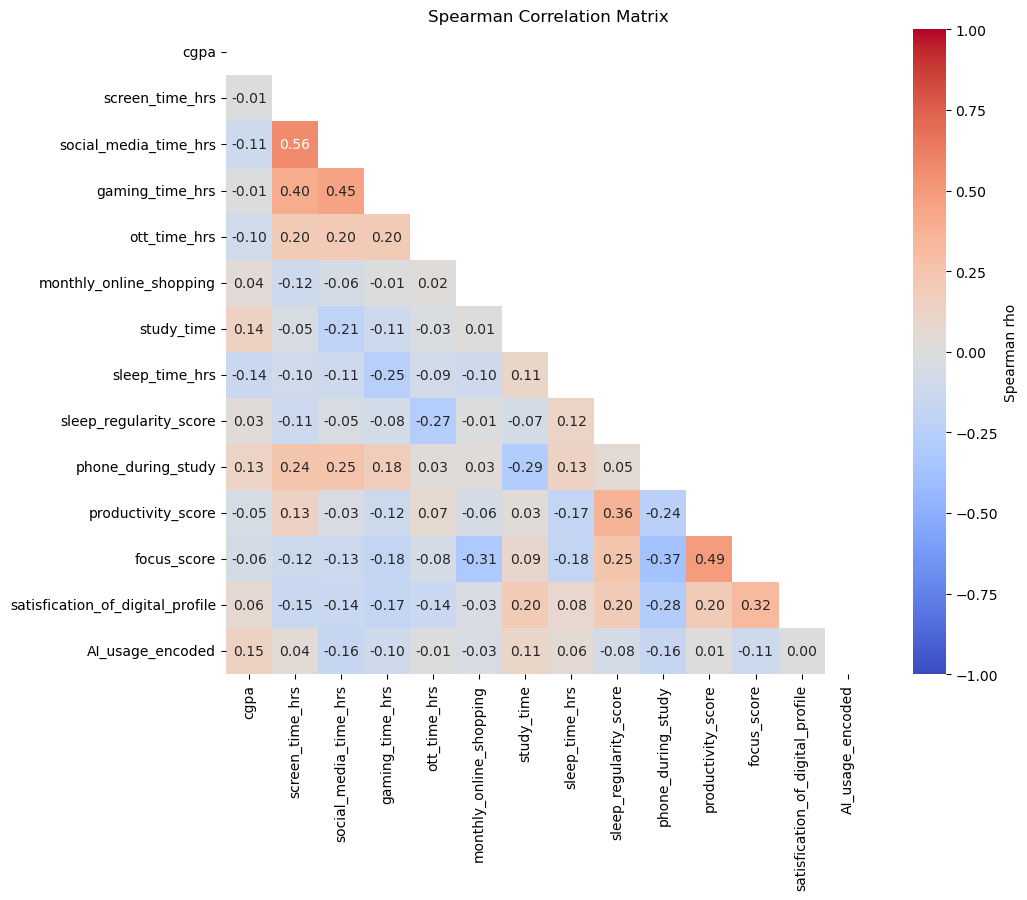

,Var 1,Var 2,rho
2,social_media_time_hrs,screen_time_hrs,0.564
65,focus_score,productivity_score,0.486
5,gaming_time_hrs,social_media_time_hrs,0.449
4,gaming_time_hrs,screen_time_hrs,0.404
64,focus_score,phone_during_study,-0.374
53,productivity_score,sleep_regularity_score,0.360
77,satisfication_of_digital_profile,focus_score,0.318
60,focus_score,monthly_online_shopping,-0.313
42,phone_during_study,study_time,-0.287
75,satisfication_of_digital_profile,phone_during_study,-0.278


In [186]:
corr_cols = scale_cols + ["sleep_regularity_score", "phone_during_study", "productivity_score",
                          "focus_score", "satisfication_of_digital_profile", "AI_usage_encoded"]
corr = df_copy[corr_cols].corr(method="spearman")

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Spearman rho"})
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

# Strongest pairs
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().rename("rho").reset_index()
pairs.columns = ["Var 1", "Var 2", "rho"]
display(pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(10).round(3))

## Time Budget: How Students Spend Screen Time

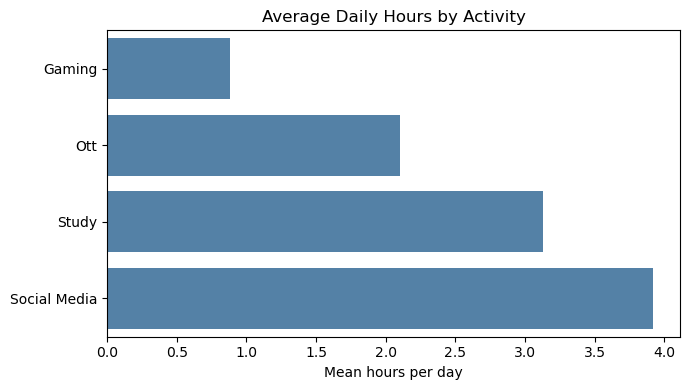

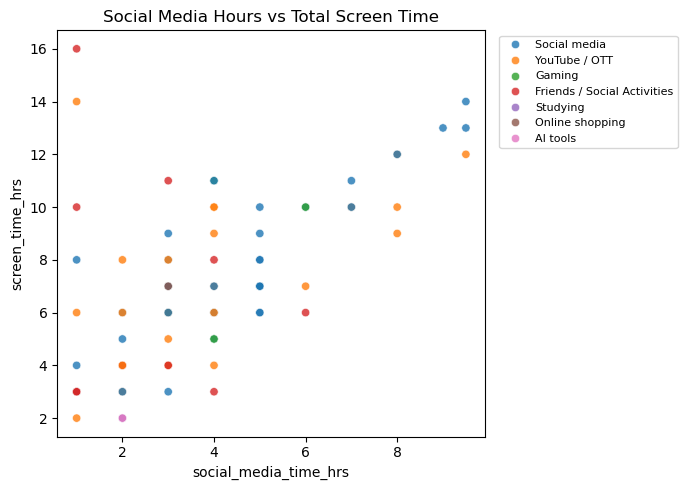

In [187]:
time_cols = ["social_media_time_hrs", "ott_time_hrs", "gaming_time_hrs", "study_time"]
means = df_copy[time_cols].mean().sort_values()
plt.figure(figsize=(7, 4))
sns.barplot(x=means.values, y=[c.replace("_hrs", "").replace("_time", "").replace("_", " ").title() for c in means.index], color="steelblue")
plt.xlabel("Mean hours per day")
plt.title("Average Daily Hours by Activity")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_copy, x="social_media_time_hrs", y="screen_time_hrs", hue="mostly_spent_activity", alpha=0.8)
plt.title("Social Media Hours vs Total Screen Time")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## AI Tool Usage: Purposes and Relationship with Study Outcomes

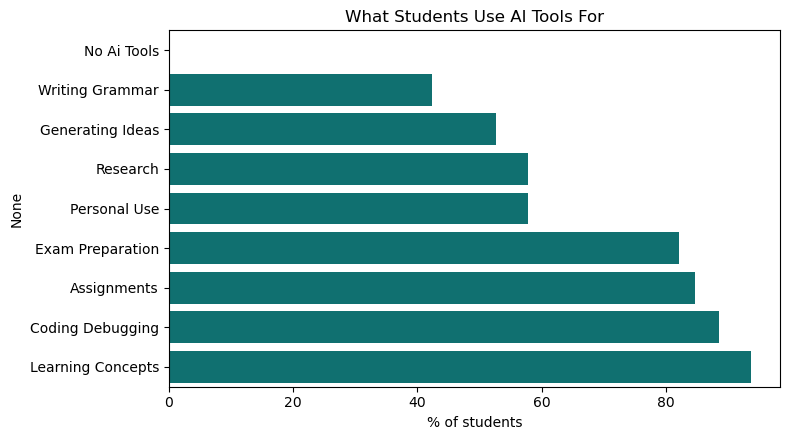

n_ai_purposes         cgpa        study_time         \
                             mean median  mean median       mean median   
AI_usage                                                                  
Daily                        5.54    5.0  8.23   8.35       2.98    3.0   
Rarely                       3.86    4.0  8.04   8.20       3.00    3.0   
Several times a day          6.22    7.0  8.48   8.40       3.48    3.0   

                    productivity_score        focus_score         
                                  mean median        mean median  
AI_usage                                                          
Daily                             3.00    3.0        2.98    3.0  
Rarely                            3.00    3.0        3.29    3.0  
Several times a day               2.91    3.0        2.78    3.0

Spearman: number of AI purposes vs CGPA: rho=0.005, p=0.9649


In [188]:
purpose_cols = [c for c in df_copy.columns if c.startswith("AI_usage_") and c not in ("AI_usage_purpose", "AI_usage_encoded")]
share = (df_copy[purpose_cols].mean() * 100).sort_values()
share.index = [c.replace("AI_usage_", "").replace("_", " ").title() for c in share.index]

plt.figure(figsize=(8, 4.5))
sns.barplot(x=share.values, y=share.index, color="teal")
plt.xlabel("% of students")
plt.title("What Students Use AI Tools For")
plt.tight_layout()
plt.show()

df_copy["n_ai_purposes"] = df_copy[[c for c in purpose_cols if c != "AI_usage_no_ai_tools"]].sum(axis=1)
display(df_copy.groupby("AI_usage", observed=True)[["n_ai_purposes", "cgpa", "study_time", "productivity_score", "focus_score"]].agg(["mean", "median"]).round(2))
rho, p = spearmanr(df_copy["n_ai_purposes"], df_copy["cgpa"])
print(f"Spearman: number of AI purposes vs CGPA: rho={rho:.3f}, p={p:.4f}")

## Sleep, Study Habits and Satisfaction

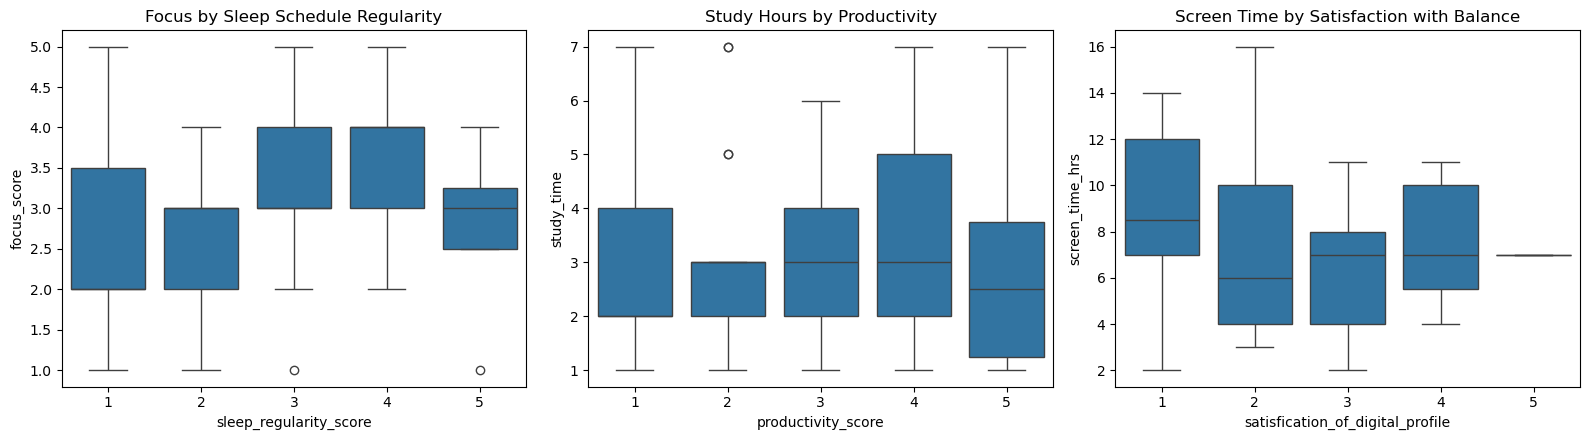

,Var 1,Var 2,rho,p-value
0,sleep_regularity_score,focus_score,0.246,0.0302
1,sleep_regularity_score,productivity_score,0.360,0.0012
2,study_time,productivity_score,0.026,0.8244
3,screen_time_hrs,satisfication_of_digital_profile,-0.153,0.1811
4,social_media_time_hrs,satisfication_of_digital_profile,-0.142,0.2139
5,study_time,satisfication_of_digital_profile,0.200,0.0788


In [189]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df_copy, x="sleep_regularity_score", y="focus_score", ax=axes[0]); axes[0].set_title("Focus by Sleep Schedule Regularity")
sns.boxplot(data=df_copy, x="productivity_score", y="study_time", ax=axes[1]); axes[1].set_title("Study Hours by Productivity")
sns.boxplot(data=df_copy, x="satisfication_of_digital_profile", y="screen_time_hrs", ax=axes[2]); axes[2].set_title("Screen Time by Satisfaction with Balance")
plt.tight_layout()
plt.show()

rows = []
for a, b in [("sleep_regularity_score", "focus_score"), ("sleep_regularity_score", "productivity_score"),
             ("study_time", "productivity_score"), ("screen_time_hrs", "satisfication_of_digital_profile"),
             ("social_media_time_hrs", "satisfication_of_digital_profile"), ("study_time", "satisfication_of_digital_profile")]:
    r, p = spearmanr(df_copy[a], df_copy[b])
    rows.append({"Var 1": a, "Var 2": b, "rho": round(r, 3), "p-value": round(p, 4)})
display(pd.DataFrame(rows))

## Summary of Findings

**Data preparation.** The raw file (83 rows) had no missing values or duplicates. Rows with an impossible age/year combination, an invalid CGPA (1.7), contradictory AI answers ("I don't use AI tools" together with other purposes) and one inconsistent response (an extreme outlier across several hour-based columns) were removed, leaving 78 rows. Columns were renamed and documented in the data dictionary, ordinal and multi-select answers were encoded, focus / productivity / sleep-regularity were reverse-coded so that higher = better, extreme values were winsorized, and min-max, z-score and log1p versions of the numeric features were created in `df_scaled`.

**Relationships found (Spearman, n = 78).**
- *Screen use clusters together*: social media time rises with total screen time (rho about 0.56) and with gaming time (about 0.45).
- *Focus and productivity go together* (rho about 0.49, p < 0.001).
- *Phone use during study hurts focus*: more phone use goes with lower focus (rho about -0.37, p < 0.001) and lower productivity (rho about -0.24, p = 0.037).
- *Regular sleep helps focus and productivity*: a more regular sleep schedule is associated with higher productivity (rho about 0.36, p = 0.001) and with better focus (rho about 0.25, p = 0.030) — both significant at the 5% level.
- *Satisfaction with the digital/study balance* is moderately higher among students who are more focused (rho about 0.32) and lower among those who use their phone more during study (rho about -0.28). It is also weakly lower for heavier screen and social media users (not significant).
- *CGPA is not significantly associated* with any single digital habit (screen, social media, gaming, OTT, sleep, study time, AI-use frequency) (all p > 0.05).

The sample is small (78), self-reported and probably a convenience sample; many tests were run without multiple-comparison correction, and nothing here establishes causation.